# Simple Demonstration: NVIDIA News Sentiment with VADER, Basic Lexicon & FinBERT
### Testing Three Natural Language Processing Approaches on Live Market Headlines

---

This notebook provides a clean, self-contained walkthrough comparing three approaches to financial text analysis:
1. **VADER**: General-purpose lexical dictionary with grammatical heuristics.
2. **Basic Financial Lexicon (Bag-of-Words)**: Simple domain word-count polarity baseline (inspired by Loughran-McDonald).
3. **FinBERT**: Pre-trained financial domain transformer model (`ProsusAI/finbert`).

We download live, real-time **NVIDIA (NVDA)** news headlines and run all three tests side by side.

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['USE_TF'] = '0'
os.environ['TRANSFORMERS_NO_TF'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import re
import urllib.request
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# important
# configure cpu thread execution for stability
import torch
torch.set_num_threads(1)

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from transformers import AutoTokenizer, AutoModelForSequenceClassification

### 1. Download Latest NVIDIA News (Example Articles)

We query the Google News RSS feed for recent NVIDIA (`NVDA`) headlines, parse the publication dates and sources, and build a structured dataset.

In [2]:
# important
# download latest nvidia news articles via rss
def download_nvidia_articles(n_items=8):
    url = "https://news.google.com/rss/search?q=NVIDIA+stock+when:7d&hl=en-US&gl=US&ceid=US:en"
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    
    with urllib.request.urlopen(req, timeout=15) as resp:
        xml_content = resp.read()
        
    root = ET.fromstring(xml_content)
    items = root.findall('.//item')[:n_items]
    
    records = []
    for it in items:
        raw_title = it.find('title').text if it.find('title') is not None else ""
        pub_date = it.find('pubDate').text if it.find('pubDate') is not None else ""
        
        # split outlet from headline
        if " - " in raw_title:
            headline, publisher = raw_title.rsplit(" - ", 1)
        else:
            headline, publisher = raw_title, "Financial Media"
            
        records.append({
            'headline': headline.strip(),
            'publisher': publisher.strip(),
            'pub_date': pub_date.strip()
        })
        
    # important
    # convert to pandas dataframe
    return pd.DataFrame(records)

# important
# fetch sample articles
df = download_nvidia_articles(n_items=8)

print(f"Downloaded {len(df)} latest NVIDIA news articles:\n")
for i, row in df.iterrows():
    print(f"[{i+1}] ({row['publisher']}) {row['headline']}")

Downloaded 8 latest NVIDIA news articles:

[1] (Yahoo Finance) 'Nothing has changed': Why some Nvidia stock bulls aren't wavering after Jensen Huang ouster
[2] (Yahoo Finance) Nvidia stock sinks 4% as chipmaker investigates CEO Jensen Huang's relationship with alleged Chinese spy
[3] (Yahoo Finance) Nvidia stock slips as investors digest CEO exit, broader chip sell-off accelerates
[4] (Yahoo Finance) Nvidia Stock Falls Below $165 After Its CEO Resigns: Is It a Bargain Buy?
[5] (Yahoo Finance) Nvidia stock tumbles as CEO Jensen Huang steps down, dragging down other AI names
[6] (Yahoo Finance) 'Icarus' rise and fall': Analyst downgrades Nvidia stock amid Jensen Huang woes, highlights risks
[7] (Yahoo Finance) Should You Buy Nvidia Stock Before Nov. 17?
[8] (Yahoo Finance) Retail investors are buying Nvidia’s stock crash like never before — history urges patience


### 2. Test 1: VADER Lexical Sentiment Analysis

- **Method**: General English dictionary lookup with grammatical modifiers (negation, capitalization, intensifiers).
- **Compound Score**:
  $$c = \frac{\sum x}{\sqrt{(\sum x)^2 + 15}} \in [-1.0, +1.0]$$
- **Classification**: Bullish ($c \ge 0.05$), Bearish ($c \le -0.05$), Neutral otherwise.

In [3]:
# important
# initialize vader sentiment analyzer
try:
    vader = SentimentIntensityAnalyzer()
except LookupError:
    nltk.download('vader_lexicon', quiet=True)
    vader = SentimentIntensityAnalyzer()

# important
# compute vader polarity scores for each article
vader_results = [vader.polarity_scores(text) for text in df['headline']]
df['vader_compound'] = [res['compound'] for res in vader_results]

# important
# classify vader compound into directional call
def get_vader_class(score):
    if score >= 0.05:
        return 'Bullish'
    elif score <= -0.05:
        return 'Bearish'
    else:
        return 'Neutral'

df['vader_class'] = df['vader_compound'].apply(get_vader_class)

print("--- Test 1: VADER Results ---")
for i, row in df[['headline', 'vader_compound', 'vader_class']].iterrows():
    print(f"[{row['vader_class']:7s}] ({row['vader_compound']:+.2f}) {row['headline']}")

--- Test 1: VADER Results ---
[Bullish] (+0.11) 'Nothing has changed': Why some Nvidia stock bulls aren't wavering after Jensen Huang ouster
[Neutral] (+0.00) Nvidia stock sinks 4% as chipmaker investigates CEO Jensen Huang's relationship with alleged Chinese spy
[Neutral] (+0.00) Nvidia stock slips as investors digest CEO exit, broader chip sell-off accelerates
[Bearish] (-0.13) Nvidia Stock Falls Below $165 After Its CEO Resigns: Is It a Bargain Buy?
[Neutral] (+0.00) Nvidia stock tumbles as CEO Jensen Huang steps down, dragging down other AI names
[Bearish] (-0.61) 'Icarus' rise and fall': Analyst downgrades Nvidia stock amid Jensen Huang woes, highlights risks
[Neutral] (+0.00) Should You Buy Nvidia Stock Before Nov. 17?
[Bearish] (-0.05) Retail investors are buying Nvidia’s stock crash like never before — history urges patience


### 3. Test 2: Basic Financial Lexicon (Bag-of-Words)

- **Method**: Simple token-matching baseline using curated positive and negative financial word lists (inspired by the Loughran-McDonald financial sentiment dictionary).
- **Polarity Score**:
  $$\text{Lexicon Score} = \frac{N_{\text{pos}} - N_{\text{neg}}}{N_{\text{pos}} + N_{\text{neg}}} \in [-1.0, +1.0]$$
  *(Returns $0.0$ if no dictionary words appear).*
- **Classification**: Bullish ($\ge 0.05$), Bearish ($\le -0.05$), Neutral otherwise.

In [4]:
# important
# basic positive and negative financial word lists
POS_WORDS = {
    'beat', 'beats', 'bull', 'bullish', 'buy', 'bargain', 'boom', 'growth',
    'gain', 'gains', 'record', 'surge', 'soar', 'rally', 'upgrade', 'up',
    'outperform', 'profit', 'profits', 'strong', 'expansion', 'upside'
}

NEG_WORDS = {
    'fall', 'falls', 'sink', 'sinks', 'slip', 'slips', 'drop', 'drops',
    'tumble', 'tumbles', 'crash', 'bear', 'bearish', 'sell', 'selloff',
    'downgrade', 'miss', 'misses', 'loss', 'losses', 'risk', 'risks',
    'resign', 'resigns', 'ouster', 'exit', 'probe', 'investigates',
    'pressure', 'restrictions', 'ban', 'plunge', 'woes', 'drag', 'cut', 'cuts'
}

# important
# compute bag of words lexicon polarity score
def score_basic_lexicon(text):
    tokens = re.findall(r"[a-z]+", text.lower())
    n_pos = sum(1 for t in tokens if t in POS_WORDS)
    n_neg = sum(1 for t in tokens if t in NEG_WORDS)
    
    total = n_pos + n_neg
    if total == 0:
        score = 0.0
    else:
        score = (n_pos - n_neg) / float(total)
        
    if score >= 0.05:
        call = 'Bullish'
    elif score <= -0.05:
        call = 'Bearish'
    else:
        call = 'Neutral'
        
    return score, call, n_pos, n_neg

# important
# apply basic lexicon scorer across all articles
lex_outputs = [score_basic_lexicon(h) for h in df['headline']]
df['lexicon_score'] = [out[0] for out in lex_outputs]
df['lexicon_class'] = [out[1] for out in lex_outputs]

print("--- Test 2: Basic Financial Lexicon Results ---")
for i, row in df[['headline', 'lexicon_score', 'lexicon_class']].iterrows():
    print(f"[{row['lexicon_class']:7s}] ({row['lexicon_score']:+.2f}) {row['headline']}")

--- Test 2: Basic Financial Lexicon Results ---
[Bearish] (-1.00) 'Nothing has changed': Why some Nvidia stock bulls aren't wavering after Jensen Huang ouster
[Bearish] (-1.00) Nvidia stock sinks 4% as chipmaker investigates CEO Jensen Huang's relationship with alleged Chinese spy
[Bearish] (-1.00) Nvidia stock slips as investors digest CEO exit, broader chip sell-off accelerates
[Neutral] (+0.00) Nvidia Stock Falls Below $165 After Its CEO Resigns: Is It a Bargain Buy?
[Bearish] (-1.00) Nvidia stock tumbles as CEO Jensen Huang steps down, dragging down other AI names
[Bearish] (-1.00) 'Icarus' rise and fall': Analyst downgrades Nvidia stock amid Jensen Huang woes, highlights risks
[Bullish] (+1.00) Should You Buy Nvidia Stock Before Nov. 17?
[Bearish] (-1.00) Retail investors are buying Nvidia’s stock crash like never before — history urges patience


### 4. Test 3: FinBERT Financial Domain Transformer

- **Method**: BERT pre-trained on financial communication and fine-tuned on the Financial PhraseBank (`ProsusAI/finbert`).
- **Tone Score**:
  $$\text{Tone} = P_{\text{positive}} - P_{\text{negative}} \in [-1.0, +1.0]$$
- **Classification**: $\arg\max(P_{\text{positive}}, P_{\text{negative}}, P_{\text{neutral}})$, mapped to Bullish, Bearish, or Neutral.

In [5]:
# important
# load pretrained finbert model and tokenizer
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
finbert = AutoModelForSequenceClassification.from_pretrained(model_name)
finbert.eval()

# important
# run forward pass per headline for memory stability
probs_list = []
with torch.no_grad():
    for text in df['headline']:
        enc = tokenizer([text], padding=True, truncation=True, max_length=64, return_tensors='pt')
        logits = finbert(**enc).logits
        p = torch.nn.functional.softmax(logits, dim=-1).numpy()[0]
        probs_list.append(p)

probs = np.array(probs_list)

# class mapping: 0 -> positive, 1 -> negative, 2 -> neutral
# important
# calculate continuous financial tone: p_pos - p_neg
df['finbert_tone'] = probs[:, 0] - probs[:, 1]

# important
# directional categorical call
label_map = {0: 'Bullish', 1: 'Bearish', 2: 'Neutral'}
df['finbert_class'] = [label_map[idx] for idx in np.argmax(probs, axis=-1)]

print("--- Test 3: FinBERT Results ---")
for i, row in df[['headline', 'finbert_tone', 'finbert_class']].iterrows():
    print(f"[{row['finbert_class']:7s}] ({row['finbert_tone']:+.2f}) {row['headline']}")

--- Test 3: FinBERT Results ---
[Neutral] (-0.09) 'Nothing has changed': Why some Nvidia stock bulls aren't wavering after Jensen Huang ouster
[Bearish] (-0.94) Nvidia stock sinks 4% as chipmaker investigates CEO Jensen Huang's relationship with alleged Chinese spy
[Bearish] (-0.94) Nvidia stock slips as investors digest CEO exit, broader chip sell-off accelerates
[Bearish] (-0.92) Nvidia Stock Falls Below $165 After Its CEO Resigns: Is It a Bargain Buy?
[Bearish] (-0.95) Nvidia stock tumbles as CEO Jensen Huang steps down, dragging down other AI names
[Bearish] (-0.95) 'Icarus' rise and fall': Analyst downgrades Nvidia stock amid Jensen Huang woes, highlights risks
[Neutral] (+0.00) Should You Buy Nvidia Stock Before Nov. 17?
[Neutral] (+0.08) Retail investors are buying Nvidia’s stock crash like never before — history urges patience


### 5. Multi-Model Comparison Table

Side-by-side comparison of the three tests across all downloaded NVIDIA articles.

In [6]:
# important
# create unified side by side summary table
summary_df = pd.DataFrame({
    'Headline': df['headline'],
    'VADER Score': df['vader_compound'].round(2),
    'VADER Call': df['vader_class'],
    'Lexicon Score': df['lexicon_score'].round(2),
    'Lexicon Call': df['lexicon_class'],
    'FinBERT Tone': df['finbert_tone'].round(2),
    'FinBERT Call': df['finbert_class']
})

# important
# print formatted comparison table
print(summary_df.to_string(index=False))

                                                                                                Headline  VADER Score VADER Call  Lexicon Score Lexicon Call  FinBERT Tone FinBERT Call
            'Nothing has changed': Why some Nvidia stock bulls aren't wavering after Jensen Huang ouster         0.11    Bullish           -1.0      Bearish         -0.09      Neutral
Nvidia stock sinks 4% as chipmaker investigates CEO Jensen Huang's relationship with alleged Chinese spy         0.00    Neutral           -1.0      Bearish         -0.94      Bearish
                      Nvidia stock slips as investors digest CEO exit, broader chip sell-off accelerates         0.00    Neutral           -1.0      Bearish         -0.94      Bearish
                               Nvidia Stock Falls Below $165 After Its CEO Resigns: Is It a Bargain Buy?        -0.13    Bearish            0.0      Neutral         -0.92      Bearish
                       Nvidia stock tumbles as CEO Jensen Huang steps down, drag

### 6. Visual Comparison of the Three Tests

Visualizing the continuous scores $[-1, 1]$ and categorical classifications across VADER, Basic Financial Lexicon, and FinBERT.

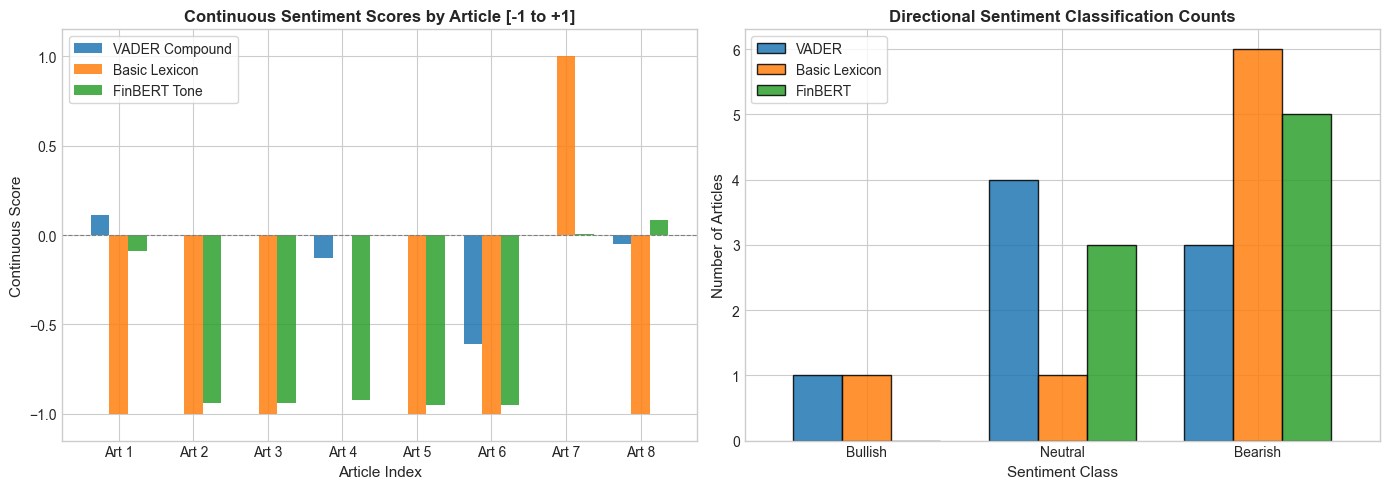

In [7]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

indices = np.arange(len(df))
width = 0.25

axes[0].bar(indices - width, df['vader_compound'], width=width, label='VADER Compound', color='#1f77b4', alpha=0.85)
axes[0].bar(indices, df['lexicon_score'], width=width, label='Basic Lexicon', color='#ff7f0e', alpha=0.85)
axes[0].bar(indices + width, df['finbert_tone'], width=width, label='FinBERT Tone', color='#2ca02c', alpha=0.85)
axes[0].set_xticks(indices)
axes[0].set_xticklabels([f"Art {i+1}" for i in range(len(df))], fontsize=10)
axes[0].set_ylim(-1.15, 1.15)
axes[0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
axes[0].set_title('Continuous Sentiment Scores by Article [-1 to +1]', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Article Index', fontsize=11)
axes[0].set_ylabel('Continuous Score', fontsize=11)
axes[0].legend(frameon=True, loc='best')

counts = pd.DataFrame({
    'VADER': df['vader_class'].value_counts(),
    'Basic Lexicon': df['lexicon_class'].value_counts(),
    'FinBERT': df['finbert_class'].value_counts()
}).reindex(['Bullish', 'Neutral', 'Bearish']).fillna(0)

counts.plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', width=0.75, alpha=0.85)
axes[1].set_title('Directional Sentiment Classification Counts', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Sentiment Class', fontsize=11)
axes[1].set_ylabel('Number of Articles', fontsize=11)
axes[1].set_xticklabels(['Bullish', 'Neutral', 'Bearish'], rotation=0)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

### 7. Key Takeaways

| Test | Model Type | Key Strength | Typical Blind Spot |
| :--- | :--- | :--- | :--- |
| **VADER** | General lexical dictionary | Fast, accounts for punctuation and negations | Missing financial context (e.g. executive ousters scored as neutral) |
| **Basic Lexicon** | Domain bag-of-words | 100% transparent, catches domain keywords | Ignores word order, negation, and sentence context |
| **FinBERT** | Domain Transformer | Captures financial phrase semantics and nuance | Higher compute requirements |

### 8. Try It Yourself: Paste Any Article

Copy and paste any financial news article or headline inside the `custom_article` triple quotes below and run the cell to evaluate it simultaneously with **VADER**, **Basic Financial Lexicon**, and **FinBERT**.

In [8]:
# important
# paste any article or headline here to test all three models
custom_article = """
NVIDIA reported record quarterly datacenter revenue driven by surging enterprise demand for Blackwell AI chips, 
beating Wall Street expectations even as analysts flag potential export restrictions and margin pressure.
"""

# important
# evaluate a custom pasted article across vader, basic lexicon, and finbert
def analyze_custom_article(text):
    clean_text = " ".join(text.strip().split())
    
    # test 1: vader
    v_res = vader.polarity_scores(clean_text)
    v_score = v_res['compound']
    v_call = get_vader_class(v_score)
    
    # test 2: basic financial lexicon
    l_score, l_call, n_pos, n_neg = score_basic_lexicon(clean_text)
    
    # test 3: finbert
    enc = tokenizer([clean_text], padding=True, truncation=True, max_length=512, return_tensors='pt')
    with torch.no_grad():
        logits = finbert(**enc).logits
        p = torch.nn.functional.softmax(logits, dim=-1).numpy()[0]
    f_tone = float(p[0] - p[1])
    f_call = label_map[int(np.argmax(p))]
    
    print("=" * 75)
    print("CUSTOM ARTICLE SENTIMENT REPORT")
    print("=" * 75)
    print(f"Input Preview: {clean_text[:120]}{'...' if len(clean_text) > 120 else ''}\n")
    print(f"[1] VADER         -> Call: {v_call:7s} | Compound: {v_score:+.3f}")
    print(f"[2] Basic Lexicon -> Call: {l_call:7s} | Score:    {l_score:+.3f} (pos={n_pos}, neg={n_neg})")
    print(f"[3] FinBERT       -> Call: {f_call:7s} | Tone:     {f_tone:+.3f} (pos={p[0]:.2f}, neg={p[1]:.2f}, neu={p[2]:.2f})")
    print("=" * 75)

# important
# run evaluation on the pasted article
analyze_custom_article(custom_article)

CUSTOM ARTICLE SENTIMENT REPORT
Input Preview: NVIDIA reported record quarterly datacenter revenue driven by surging enterprise demand for Blackwell AI chips, beating ...

[1] VADER         -> Call: Bearish | Compound: -0.691
[2] Basic Lexicon -> Call: Bearish | Score:    -0.333 (pos=1, neg=2)
[3] FinBERT       -> Call: Bullish | Tone:     +0.904 (pos=0.94, neg=0.04, neu=0.02)
